     Policy  Seed  Cargo delivered  Storm knock-outs
   Baseline    11              132                 4
   Baseline    12              132                 8
   Baseline    13              140                 2
Model-based    11              134                 0
Model-based    12              128                 0
Model-based    13              130                 0

Averages per policy
             Cargo delivered  Storm knock-outs
Policy                                        
Baseline              134.67              4.67
Model-based           130.67              0.00

Repeatability check passed (same seed -> same result)


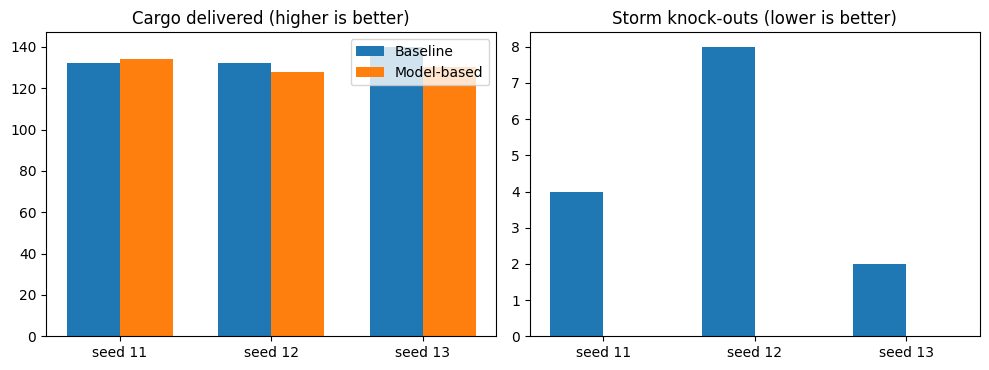

In [1]:
"""Stormwatch Harbour - core simulation (grid, ships, storms, Lookout, Quartermaster)."""
import random
from dataclasses import dataclass, field

# ---- Fixed settings from the assignment ------------------------------------
COLS, ROWS = 24, 16
RUN_TICKS = 600
N_WORKERS = 10
ARRIVAL_MIN, ARRIVAL_MAX = 6, 10      # ticks between ship arrivals
N_STORMS = 3
CARGO_PER_SHIP = 8
STORM_LEN = 15
WARN_LEAD = 5                         # Lookout warns 5 ticks before a storm

# ---- Cells I chose (col, row); row 0 = north edge, row 15 = south edge ----
BERTHS = {"B1": (3, 0), "B2": (9, 0), "B3": (14, 0), "B4": (20, 0)}
UNSAFE_BERTHS = ("B1", "B4")
WAREHOUSE = (0, 15)                   # south-west corner

# ---- My own design assumption (the brief does not define "knock-out") ------
KO_TICKS = 30                         # a knocked-out worker is disabled this long
                                      # and loses any cargo it was carrying


@dataclass
class Ship:
    id: int
    cargo_left: int = CARGO_PER_SHIP
    held_until: int = 0               # set by Harbour Master hold_ship()


@dataclass
class Worker:
    id: int
    pos: tuple
    berth: str = None                 # berth the Quartermaster assigned
    carrying: bool = False
    ko_until: int = 0
    mem: dict = field(default_factory=dict)   # model-based agent's memory


def dist(a, b):
    return abs(a[0] - b[0]) + abs(a[1] - b[1])


def step_toward(pos, target, y_first=False):
    """One-cell move. Going TO a berth: sideways first, then north (so a worker never
    walks along row 0 through another berth's cell). Going HOME: south first."""
    x, y = pos
    tx, ty = target
    if y_first and y != ty:
        return (x, y + (1 if ty > y else -1))
    if x != tx:
        return (x + (1 if tx > x else -1), y)
    if y != ty:
        return (x, y + (1 if ty > y else -1))
    return pos


class Harbour:
    def __init__(self, seed, policy, hm=None):
        self.rng = random.Random(seed)            # the ONE seeded generator
        self.t = 0
        self.policy = policy
        self.hm = hm                              # None => Lookout warns workers directly
        self.workers = [Worker(i, WAREHOUSE) for i in range(N_WORKERS)]
        self.berth_ship = {b: None for b in BERTHS}
        self.waiting = []
        self.next_ship_id = 1
        self.storms = self._make_storms()         # list of storm start ticks
        self.next_arrival = self.rng.randint(ARRIVAL_MIN, ARRIVAL_MAX)
        self.delivered = 0
        self.knockouts = 0
        self.cargo_lost = 0
        self.alerted = False                      # have workers been told about the current storm?
        self.log = []

    # -- storms ---------------------------------------------------------------
    def _make_storms(self):
        windows = [(40, 180), (220, 360), (400, 570)]      # keeps storms apart
        return [self.rng.randint(lo, hi) for lo, hi in windows][:N_STORMS]

    def storm_active(self, t=None):
        t = self.t if t is None else t
        return any(s <= t < s + STORM_LEN for s in self.storms)

    def warning_storm(self):
        """Start tick of the storm the Lookout is currently warning about (or None)."""
        for s in self.storms:
            if s - WARN_LEAD <= self.t < s + STORM_LEN:
                return s
        return None

    def broadcast_warning(self, storm_start):
        for w in self.workers:
            self.policy.on_percept(w, ("storm_warning", storm_start))
        self.alerted = True

    # -- one tick ------------------------------------------------------------
    def step(self):
        t = self.t
        # 1. Lookout sees the storm coming
        for s in self.storms:
            if t == s - WARN_LEAD:
                self.alerted = False
                if self.hm is None:
                    self.broadcast_warning(s)     # direct Lookout -> workers channel
        # 2. Harbour Master (LLM) is consulted around storms
        if self.hm is not None and self._hm_due():
            self.hm.decide(self)
        # 3. ships arrive and dock
        if t == self.next_arrival:
            self.waiting.append(Ship(self.next_ship_id))
            self.next_ship_id += 1
            self.next_arrival += self.rng.randint(ARRIVAL_MIN, ARRIVAL_MAX)
        for b in BERTHS:
            if self.berth_ship[b] is None:
                for ship in self.waiting:
                    if ship.held_until <= t:
                        self.waiting.remove(ship)
                        self.berth_ship[b] = ship
                        break
        # 4. Quartermaster assigns idle workers to berths
        for w in self.workers:
            self.policy.pre_act(w, self)
        for w in self.workers:
            if w.ko_until > t or w.carrying or w.berth:
                continue
            best = None
            for b in self.policy.allowed_berths(w, self):
                ship = self.berth_ship[b]
                if ship and ship.cargo_left - self._claims(b) > 0:
                    key = (dist(w.pos, BERTHS[b]), b)
                    if best is None or key < best[0]:
                        best = (key, b)
            if best:
                w.berth = best[1]
        # 5. workers act
        for w in self.workers:
            if w.ko_until > t:
                continue
            self._act(w)
        # 6. storm hits anyone standing on an unsafe berth
        if self.storm_active():
            for w in self.workers:
                if w.ko_until <= t and any(w.pos == BERTHS[b] for b in UNSAFE_BERTHS):
                    w.ko_until = t + KO_TICKS
                    w.berth = None
                    if w.carrying:
                        w.carrying = False
                        self.cargo_lost += 1
                    self.knockouts += 1
        self.t += 1

    def _hm_due(self):
        return any(self.t in (s - WARN_LEAD, s, s + 5, s + 10) for s in self.storms)

    def _claims(self, b):
        return sum(1 for w in self.workers if w.berth == b and not w.carrying)

    def _act(self, w):
        if w.carrying:
            if w.pos == WAREHOUSE:
                self.delivered += 1
                w.carrying = False
            else:
                w.pos = step_toward(w.pos, WAREHOUSE, y_first=True)
        elif w.berth:
            bp = BERTHS[w.berth]
            if w.pos == bp:
                ship = self.berth_ship[w.berth]
                if ship and ship.cargo_left > 0:
                    ship.cargo_left -= 1
                    w.carrying = True
                    if ship.cargo_left == 0:
                        self.berth_ship[w.berth] = None    # ship sails away
                w.berth = None
            else:
                w.pos = step_toward(w.pos, bp)
        elif self.policy.retreat(w, self):
            w.pos = step_toward(w.pos, WAREHOUSE, y_first=True)

    def run(self):
        while self.t < RUN_TICKS:
            self.step()
        return {"delivered": self.delivered, "knockouts": self.knockouts,
                "cargo_lost": self.cargo_lost}


# ============================ DOCKWORKER POLICIES ============================


class BaselinePolicy:
    name = "baseline"

    def on_percept(self, worker, percept):          # ignores the Lookout
        pass

    def pre_act(self, worker, env):
        pass

    def allowed_berths(self, worker, env):          # any berth is fine
        return list(BERTHS)

    def retreat(self, worker, env):
        return False


class ModelBasedPolicy:
    name = "model"

    def on_percept(self, worker, percept):
        kind, start = percept
        if kind == "storm_warning":
            worker.mem["storm_start"] = start       # REMEMBER it

    def _avoid(self, worker, t):
        """Berths this worker believes are unsafe right now (from memory)."""
        s = worker.mem.get("storm_start")
        if s is not None and s - WARN_LEAD <= t < s + STORM_LEN:
            return UNSAFE_BERTHS
        return ()

    def pre_act(self, worker, env):
        # drop an assignment to a berth that is about to become unsafe
        if worker.berth in self._avoid(worker, env.t) and not worker.carrying:
            worker.berth = None

    def allowed_berths(self, worker, env):
        avoid = self._avoid(worker, env.t)
        return [b for b in BERTHS if b not in avoid]

    def retreat(self, worker, env):
        # idle on an unsafe berth cell during the danger window: walk away
        return any(worker.pos == BERTHS[b] for b in self._avoid(worker, env.t))


# ============================ EXPERIMENT (Task 2) ============================
import pandas as pd
import matplotlib.pyplot as plt

SEEDS = [11, 12, 13]          # use [11, 12, 13, 14, 15] if your instructor wants 5 seeds
POLICIES = {"Baseline": BaselinePolicy, "Model-based": ModelBasedPolicy}

rows = []
for name, cls in POLICIES.items():
    for seed in SEEDS:
        r = Harbour(seed, cls()).run()
        rows.append({"Policy": name, "Seed": seed,
                     "Cargo delivered": r["delivered"], "Storm knock-outs": r["knockouts"]})
df = pd.DataFrame(rows)
print(df.to_string(index=False))

avg = df.groupby("Policy")[["Cargo delivered", "Storm knock-outs"]].mean().round(2)
print("\nAverages per policy")
print(avg)

# repeatability check: same seed twice -> identical result
assert Harbour(11, BaselinePolicy()).run() == Harbour(11, BaselinePolicy()).run()
print("\nRepeatability check passed (same seed -> same result)")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
for j, col in enumerate(["Cargo delivered", "Storm knock-outs"]):
    for i, name in enumerate(POLICIES):
        vals = df[df.Policy == name][col].tolist()
        ax[j].bar([k + (i - 0.5) * 0.35 for k in range(len(SEEDS))], vals, 0.35, label=name)
    ax[j].set_xticks(range(len(SEEDS)))
    ax[j].set_xticklabels([f"seed {s}" for s in SEEDS])
    ax[j].set_title(col + (" (higher is better)" if j == 0 else " (lower is better)"))
ax[0].legend()
plt.tight_layout()
plt.savefig("task2_chart.png", dpi=150)
plt.show()
df.to_csv("task2_results.csv", index=False)